# Data extraction
What was extracted from Wikidata for the 13 million humans: field coverage (Table 1), unique values per property (Table 2) and the most notable individuals per Wikipedia sphere (Table 3).

In [1]:
import sys
import tempfile

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *
from identifiers import person_identifier_pids

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
TOP_N = 10

pl.Config.set_tbl_rows(50)
pl.Config.set_fmt_str_lengths(80)
apply_style()

## Connect

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
con.execute('SET VARIABLE person_pids = ?::VARCHAR[]', [person_identifier_pids()])

## Load data
### Individuals with at least one value per property

In [3]:
coverage_wide = con.sql('''
    SELECT
        COUNT(*)                                                           AS total,
        COUNT(*) FILTER (WHERE len(list_filter(individual.birth_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)          AS birth_date,
        COUNT(*) FILTER (WHERE len(list_filter(individual.death_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)          AS death_date,
        COUNT(*) FILTER (WHERE len(list_filter(individual.floruit_date, recorded -> recorded.field_provenance['year'].rule IS NULL)) > 0)        AS floruit_date,
        COUNT(individual.place_of_birth.entity.qid)                        AS place_of_birth,
        COUNT(individual.place_of_death.entity.qid)                        AS place_of_death,
        COUNT(*) FILTER (WHERE len(individual.country_of_citizenship) > 0) AS country_of_citizenship,
        COUNT(*) FILTER (WHERE len(individual.occupation) > 0)             AS occupation,
        COUNT(individual.sex_or_gender)                                    AS gender,
        COUNT(*) FILTER (WHERE len(individual.writing_language) > 0)       AS writing_language,
        COUNT(*) FILTER (WHERE len(individual.sitelink) > 0)               AS sitelink,
        COUNT(*) FILTER (WHERE len(list_filter(individual.external_id, identifier_value -> list_contains(getvariable('person_pids'), identifier_value.pid))) > 0) AS external_id,
        COUNT(*) FILTER (WHERE len(individual.work) > 0)                   AS work
    FROM individual
''').pl()
coverage_wide

total,birth_date,death_date,floruit_date,place_of_birth,place_of_death,country_of_citizenship,occupation,gender,writing_language,sitelink,external_id,work
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
13002840,7487873,3531410,68639,3724761,1585470,5569980,9038068,8965380,225824,4959526,8674206,2890462


### Unique values per property

In [4]:
UNIQUE_VALUE_QUERIES = {
    'Place of birth (P19)': 'SELECT COUNT(DISTINCT individual.place_of_birth.entity.qid) FROM individual',
    'Place of death (P20)': 'SELECT COUNT(DISTINCT individual.place_of_death.entity.qid) FROM individual',
    'Country of citizenship (P27)': 'SELECT COUNT(DISTINCT citizenship.entity.qid) FROM individual, UNNEST(individual.country_of_citizenship) AS t(citizenship)',
    'Occupation (P106)': 'SELECT COUNT(DISTINCT held_occupation.entity.qid) FROM individual, UNNEST(individual.occupation) AS t(held_occupation)',
    'Sex or gender (P21)': 'SELECT COUNT(DISTINCT individual.sex_or_gender) FROM individual',
    'Writing language (P6886)': 'SELECT COUNT(DISTINCT language) FROM individual, UNNEST(individual.writing_language) AS t(language)',
    'Wikimedia projects (sitelinks)': 'SELECT COUNT(DISTINCT individual_sitelink.site_url) FROM individual_sitelink',
    'External identifier systems (people)': "SELECT COUNT(DISTINCT individual_identifier.pid) FROM individual_identifier WHERE list_contains(getvariable('person_pids'), individual_identifier.pid)",
    'Works': 'SELECT COUNT(DISTINCT individual_work.work_qid) FROM individual_work',
    'Work types (P31 of works)': 'SELECT COUNT(DISTINCT work_type.qid) FROM work, UNNEST(work.instance_of) AS t(work_type)',
}
unique_values = pl.DataFrame({
    'Property': list(UNIQUE_VALUE_QUERIES),
    'Unique values': [con.sql(query).fetchone()[0] for query in UNIQUE_VALUE_QUERIES.values()],
})
unique_values

Property,Unique values
str,i64
"""Place of birth (P19)""",275509
"""Place of death (P20)""",130604
"""Country of citizenship (P27)""",3638
"""Occupation (P106)""",22037
"""Sex or gender (P21)""",44
"""Writing language (P6886)""",524
"""Wikimedia projects (sitelinks)""",607
"""External identifier systems (people)""",2073
"""Works""",17033394


### Records linked to individuals

In [5]:
records = con.sql('''
    SELECT
        (SELECT COUNT(*) FROM individual_sitelink)    AS sitelinks,
        (SELECT COUNT(*) FROM individual_identifier WHERE list_contains(getvariable('person_pids'), individual_identifier.pid)) AS identifier_records,
        (SELECT COUNT(*) FROM individual_work)        AS person_work_links,
        (SELECT COUNT(*) FROM work)                   AS works,
        (SELECT COUNT(*) FROM place)                  AS places,
        (SELECT COUNT(*) FROM identifier)             AS identifier_properties
''').pl()
records

sitelinks,identifier_records,person_work_links,works,places,identifier_properties
i64,i64,i64,i64,i64,i64
15543581,35958698,38487016,17050395,361751,10198


### Metadata of places, works and identifier systems

In [6]:
place_metadata = con.sql('''
    SELECT COUNT(*) AS places,
           COUNT(place.coordinates) AS with_coordinates,
           COUNT(place.sitelink) AS with_wikipedia_url,
           COUNT(place.existence.inception) AS with_inception,
           COUNT(place.existence.dissolution) AS with_dissolution,
           COUNT(*) FILTER (WHERE len(place.instance_of) > 0) AS with_instance_of
    FROM place
''').pl()
work_metadata = con.sql('''
    SELECT COUNT(*) AS works,
           COUNT(*) FILTER (WHERE len(work.instance_of) > 0) AS with_instance_of,
           COUNT(work.publication_date) AS with_publication_date,
           COUNT(work.inception) AS with_inception,
           COUNT(*) FILTER (WHERE work.publication_date IS NOT NULL OR work.inception IS NOT NULL) AS with_any_date
    FROM work
''').pl()
identifier_metadata = con.sql('''
    SELECT COUNT(*) AS identifier_properties,
           COUNT(identifier.issuer) AS with_issuer,
           COUNT(identifier.issuer_country) AS with_country,
           COUNT(identifier.number_of_records) AS with_number_of_records
    FROM identifier
''').pl()
display(place_metadata, work_metadata, identifier_metadata)

places,with_coordinates,with_wikipedia_url,with_inception,with_dissolution,with_instance_of
i64,i64,i64,i64,i64,i64
361751,346267,255502,72892,13530,359250


works,with_instance_of,with_publication_date,with_inception,with_any_date
i64,i64,i64,i64,i64
17050395,17041135,14857895,942261,15782870


identifier_properties,with_issuer,with_country,with_number_of_records
i64,i64,i64,i64
10198,3203,6097,3836


### Gender categories

In [7]:
genders = con.sql('''
    SELECT individual.sex_or_gender AS gender_qid, COUNT(*) AS individuals
    FROM individual GROUP BY 1 ORDER BY individuals DESC
''').pl()
genders.head(8)

gender_qid,individuals
str,i64
"""Q6581097""",6109758
null,4037460
"""Q6581072""",2849317
"""Q1052281""",2648
"""Q48270""",1538
"""Q2449503""",659
"""Q113124952""",514
"""Q12964198""",135


### Wikipedia editions with a page on each individual, by sphere
Read from `individual_enriched.notability`, written by `scripts/4-database_enrichment/06_individual_notability.py`: editions counted once each, split on `sitelink.is_western`; editions on neither list are left out. The cross-cultural score is the geometric mean of the two counts.

In [8]:
editions = con.sql('''
    SELECT sitelink.is_western, COUNT(*) AS editions
    FROM sitelink GROUP BY 1 ORDER BY 1
''').pl()

notability = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           individual_enriched.notability.number_of_western_editions AS western_editions,
           individual_enriched.notability.number_of_non_western_editions AS non_western_editions,
           individual_enriched.notability.cross_cultural_score AS cross_cultural_score
    FROM individual_enriched
    WHERE individual_enriched.notability.number_of_western_editions + individual_enriched.notability.number_of_non_western_editions > 0
''').pl()
assert notability['qid'].is_unique
print('individuals with at least one Western or non-Western edition:', notability.height)
display(editions, notability.head())

individuals with at least one Western or non-Western edition: 4714476


is_western,editions
bool,i64
false,98
true,75
null,434


qid,name,western_editions,non_western_editions,cross_cultural_score
str,str,i64,i64,f64
"""Q10000001""","""Tatyana Kolotilshchikova""",0,1,0.0
"""Q1000002""","""Claus Hammel""",1,1,1.0
"""Q1000005""","""Karel Matěj Čapek-Chod""",8,2,4.0
"""Q1000006""","""Florian Eichinger""",2,0,0.0
"""Q10000101""","""Eliška Hladilová""",1,0,0.0


## Preprocessing
### Field coverage table

In [9]:
PROPERTY_LABELS = {
    'total': 'All individuals (P31 = Q5)',
    'birth_date': 'Date of birth (P569)',
    'death_date': 'Date of death (P570)',
    'floruit_date': 'Floruit (P1317)',
    'place_of_birth': 'Place of birth (P19)',
    'place_of_death': 'Place of death (P20)',
    'country_of_citizenship': 'Country of citizenship (P27)',
    'occupation': 'Occupation (P106)',
    'gender': 'Sex or gender (P21)',
    'writing_language': 'Writing language (P6886)',
    'sitelink': 'Wikimedia sitelink (at least one)',
    'external_id': 'External identifier of a person (at least one)',
    'work': 'Work (at least one)',
}
total_individuals = coverage_wide['total'].item()
coverage = (
    coverage_wide.transpose(include_header=True, header_name='Property', column_names=['Individuals'])
    .with_columns(
        (pl.col('Individuals') / total_individuals * 100).round(1).alias('% of individuals'),
        pl.col('Property').replace(PROPERTY_LABELS),
    )
)
assert coverage['% of individuals'].max() <= 100
coverage

Property,Individuals,% of individuals
str,i64,f64
"""All individuals (P31 = Q5)""",13002840,100.0
"""Date of birth (P569)""",7487873,57.6
"""Date of death (P570)""",3531410,27.2
"""Floruit (P1317)""",68639,0.5
"""Place of birth (P19)""",3724761,28.6
"""Place of death (P20)""",1585470,12.2
"""Country of citizenship (P27)""",5569980,42.8
"""Occupation (P106)""",9038068,69.5
"""Sex or gender (P21)""",8965380,68.9


### Most notable individuals per sphere

In [10]:
RANKINGS = {'western_editions': 'Western editions', 'non_western_editions': 'Non-Western editions', 'cross_cultural_score': 'Cross-cultural score'}

def top_names(column):
    return notability.sort([column, 'qid'], descending=[True, False]).head(TOP_N)['name']

top_individuals = pl.DataFrame({'Rank': list(range(1, TOP_N + 1)), **{label: top_names(column) for column, label in RANKINGS.items()}})
for column in RANKINGS:
    display(notability.sort([column, 'qid'], descending=[True, False]).head(TOP_N).select('name', 'western_editions', 'non_western_editions', 'cross_cultural_score'))
top_individuals

name,western_editions,non_western_editions,cross_cultural_score
str,i64,i64,f64
"""Ronald Reagan""",75,81,77.942286
"""Michael Jackson""",74,84,78.841613
"""Jesus Christ""",74,84,78.841613
"""Basshunter""",74,55,63.796552
"""Donald Trump""",73,83,77.839579
"""Wolfgang Amadeus Mozart""",72,66,68.934752
"""Barack Obama""",72,82,76.837491
"""Isaac Newton""",71,77,73.939164
"""George W. Bush""",70,71,70.498227


name,western_editions,non_western_editions,cross_cultural_score
str,i64,i64,f64
"""Nelson Mandela""",68,87,76.915538
"""Michael Jackson""",74,84,78.841613
"""Jesus Christ""",74,84,78.841613
"""Donald Trump""",73,83,77.839579
"""Barack Obama""",72,82,76.837491
"""The Buddha""",60,81,69.7137
"""Ronald Reagan""",75,81,77.942286
"""Adolf Hitler""",70,79,74.36397
"""Leonardo da Vinci""",67,78,72.291078


name,western_editions,non_western_editions,cross_cultural_score
str,i64,i64,f64
"""Michael Jackson""",74,84,78.841613
"""Jesus Christ""",74,84,78.841613
"""Ronald Reagan""",75,81,77.942286
"""Donald Trump""",73,83,77.839579
"""Nelson Mandela""",68,87,76.915538
"""Barack Obama""",72,82,76.837491
"""Adolf Hitler""",70,79,74.36397
"""Isaac Newton""",71,77,73.939164
"""Joe Biden""",70,75,72.456884


Rank,Western editions,Non-Western editions,Cross-cultural score
i64,str,str,str
1,"""Ronald Reagan""","""Nelson Mandela""","""Michael Jackson"""
2,"""Michael Jackson""","""Michael Jackson""","""Jesus Christ"""
3,"""Jesus Christ""","""Jesus Christ""","""Ronald Reagan"""
4,"""Basshunter""","""Donald Trump""","""Donald Trump"""
5,"""Donald Trump""","""Barack Obama""","""Nelson Mandela"""
6,"""Wolfgang Amadeus Mozart""","""The Buddha""","""Barack Obama"""
7,"""Barack Obama""","""Ronald Reagan""","""Adolf Hitler"""
8,"""Isaac Newton""","""Adolf Hitler""","""Isaac Newton"""
9,"""George W. Bush""","""Leonardo da Vinci""","""Joe Biden"""


## Tables
### Table 1: Individuals with at least one value per extracted property

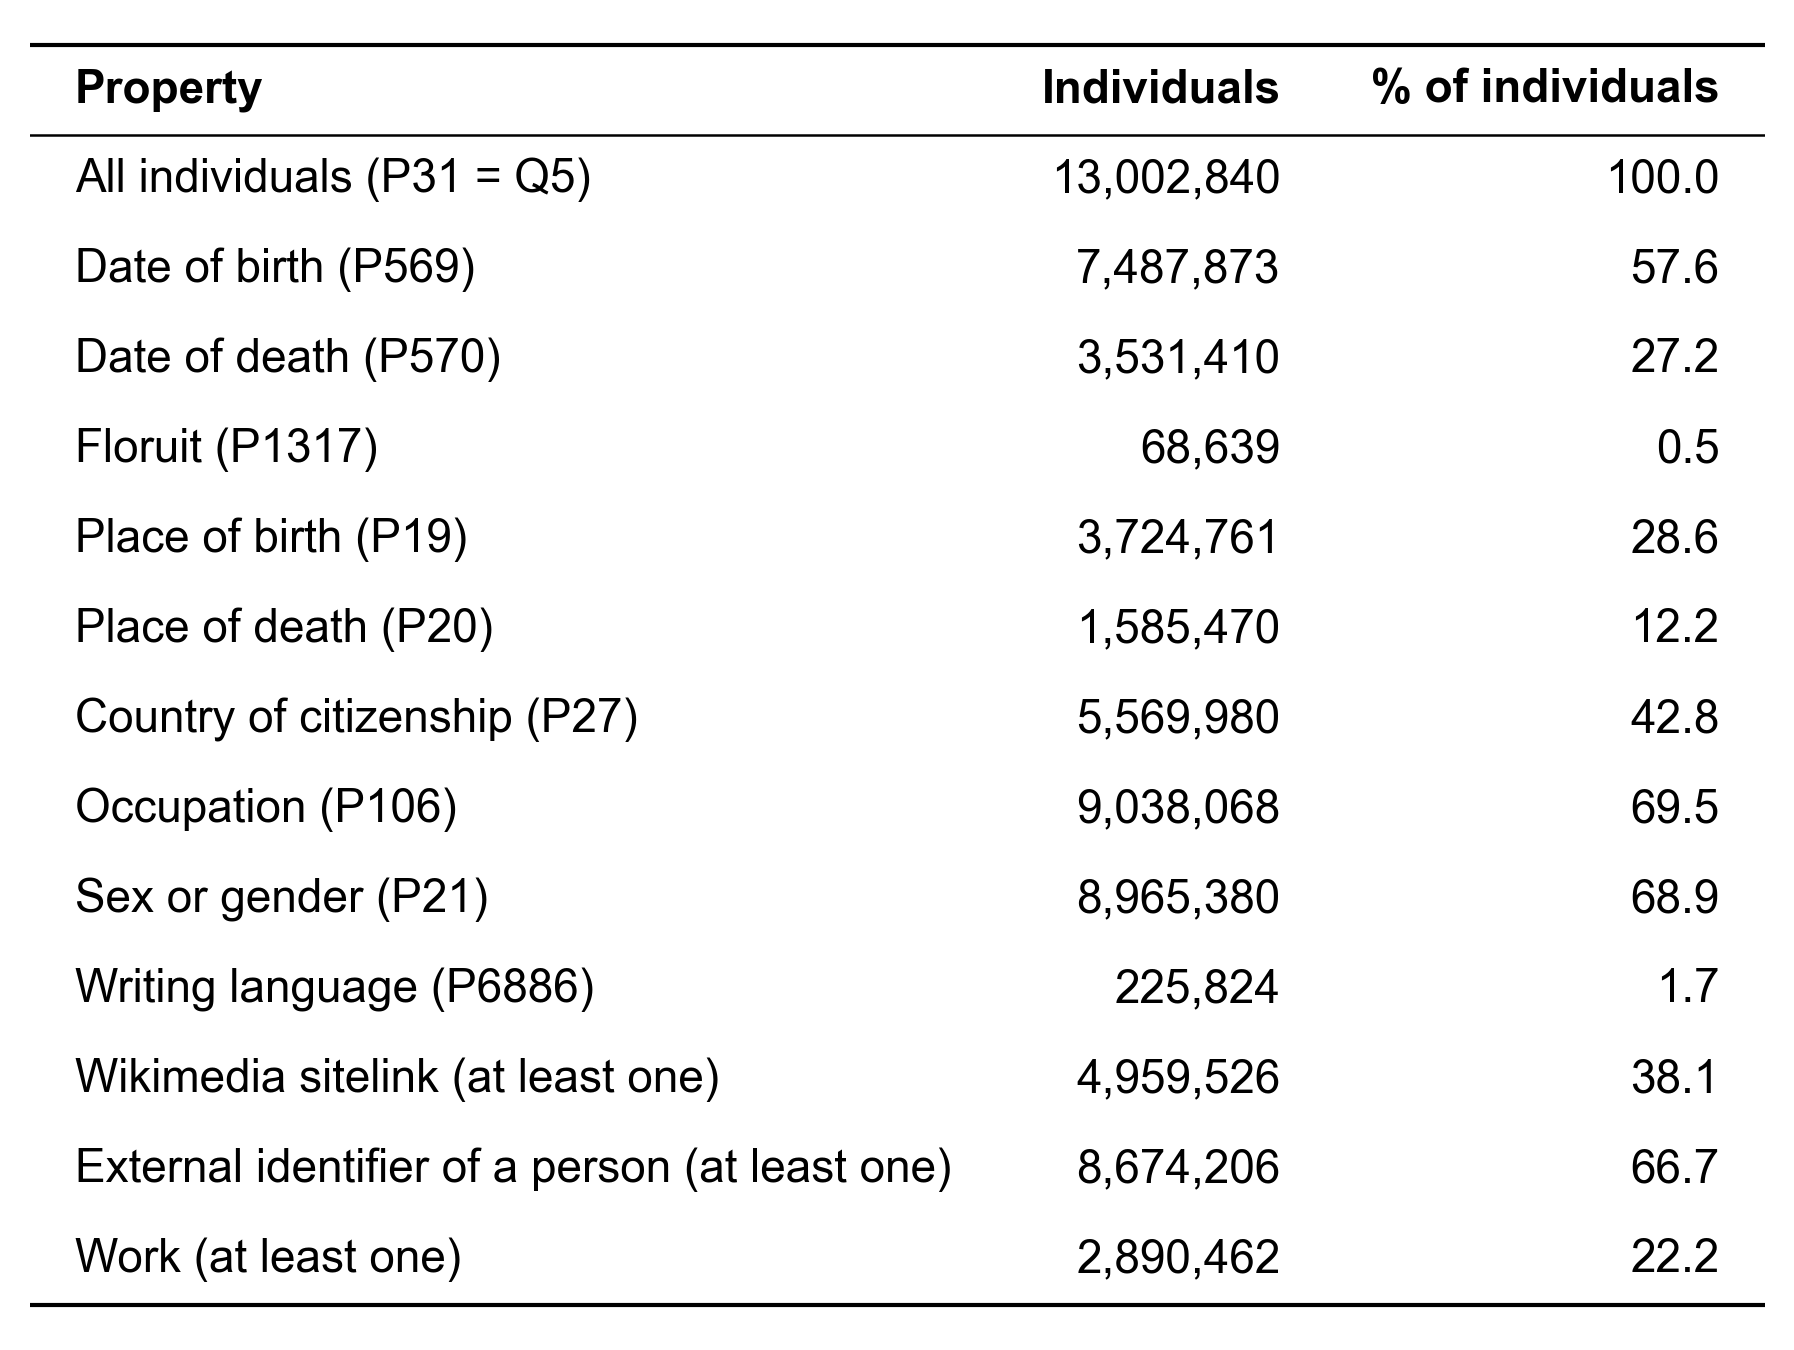

In [11]:
show_table(coverage, decimals=1)

### Table 2: Unique values per extracted property

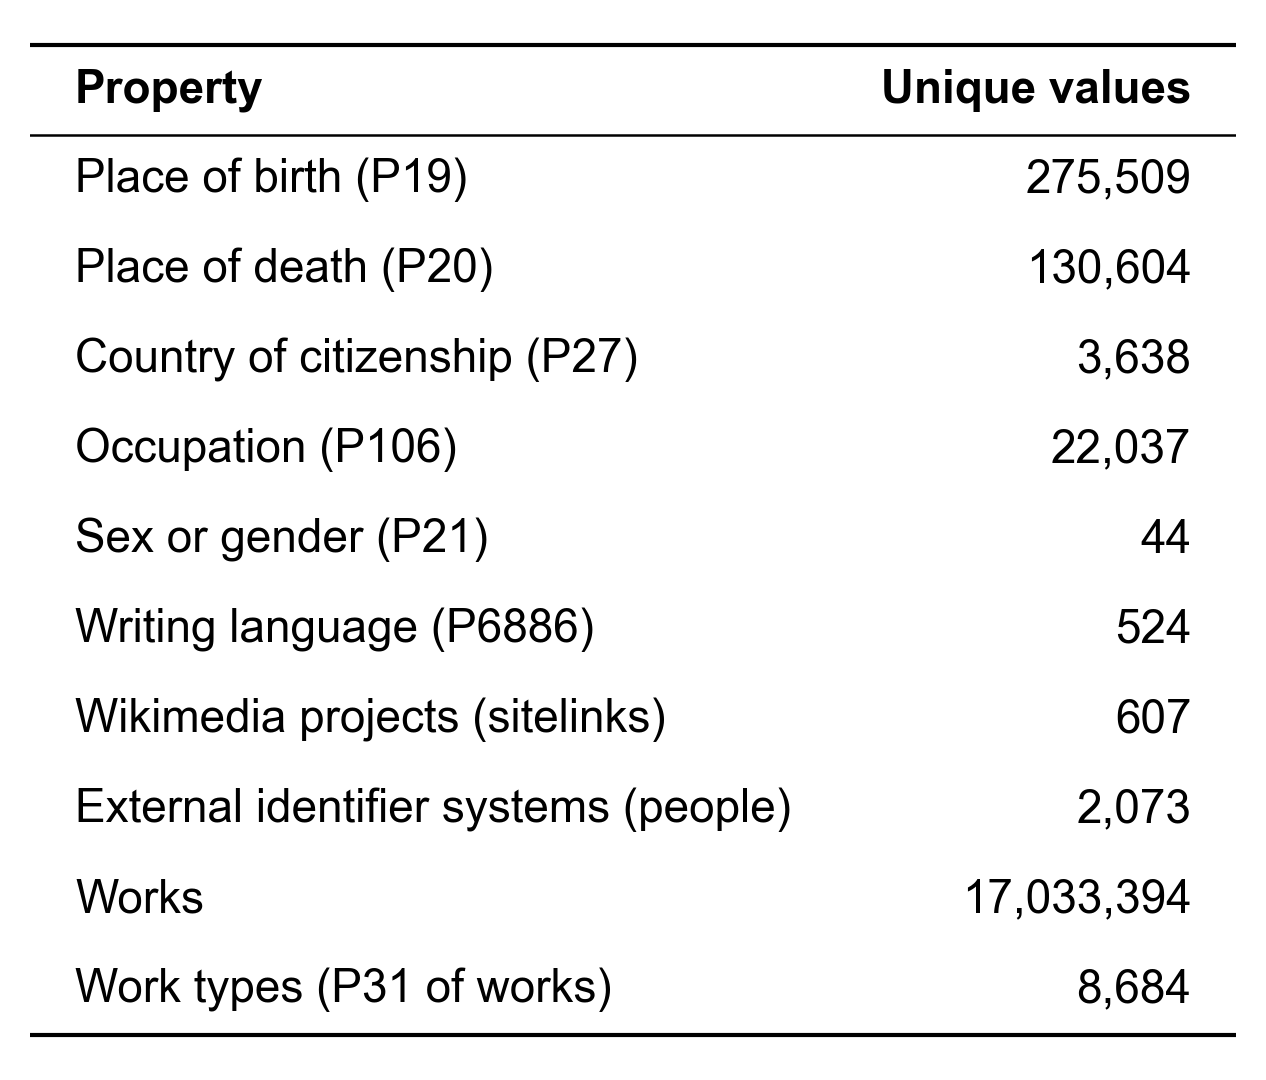

In [12]:
show_table(unique_values)

### Table 3: Most notable individuals in Western and non-Western Wikipedia editions

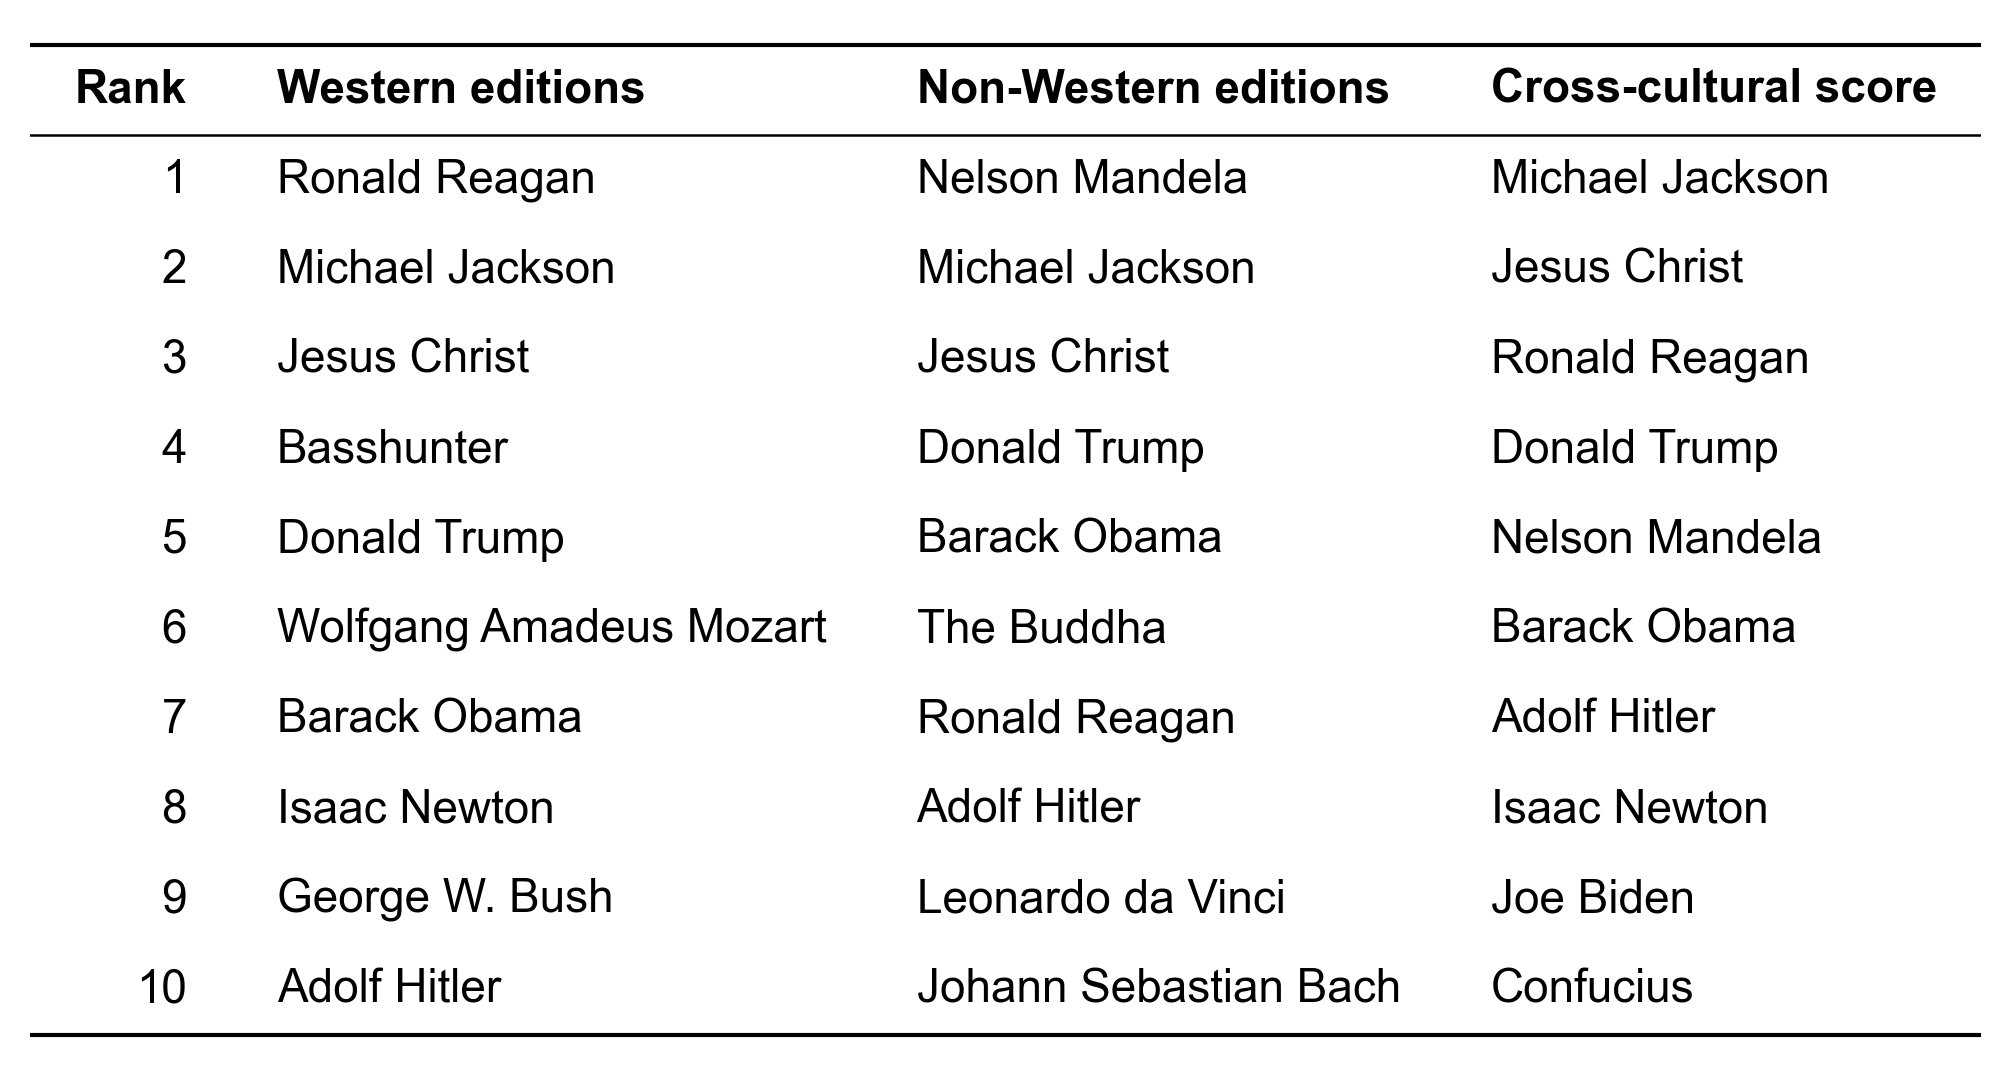

In [13]:
show_table(top_individuals)